In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset from the uploaded CSV file
df = pd.read_csv('BLC C3 final.csv')

# Preprocess features: Convert text strings to numeric and fill missing values with 0.0
df['Reviews_Cleaned'] = pd.to_numeric(df['Reviews'], errors='coerce').fillna(0.0)
df['Comments_Cleaned'] = pd.to_numeric(df['Comment'], errors='coerce').fillna(0.0)

# Clean and normalize business categories
df['Category'] = df['Category'].fillna('Unknown').str.strip().str.title()

print(f"Dataset successfully loaded. Total rows: {len(df)}")
df[['S.No', 'Company', 'Category', 'Reviews_Cleaned', 'Comments_Cleaned']].head()

Dataset successfully loaded. Total rows: 301


,S.No,Company,Category,Reviews_Cleaned,Comments_Cleaned
0,1199,The cake corne,Cake Shop And Bakery,4.9,155
1,1200,FNP CAKES N MORE by Ferns N Petals (Patna),Cake Shop And Bakery,4.8,147
2,1201,Mr.bakers,Cake Shop And Bakery,4.3,172
3,1202,Monginis Cake Shop,Cake Shop And Bakery,4.2,1554
4,1203,Downtown La Pasteleria,Cake Shop And Bakery,4.6,36


In [2]:
import os

In [3]:
print(df.columns.tolist())

['S.No', 'Country', 'City', 'Company', 'LINKEDIN LINK', 'Website', 'Tech Need / Problem', 'EMAIL', 'CONTACT', 'Google Map', 'Category', 'Reviews', 'Comment', 'Reviews_Cleaned', 'Comments_Cleaned']


In [4]:
import pandas as pd
import numpy as np
...
df = pd.read_csv('BLC C3 final.csv')

In [5]:
# Re-create the cleaned columns if they are missing

df['Reviews_Cleaned'] = pd.to_numeric(
    df['Reviews'],
    errors='coerce'
)

df['Comments_Cleaned'] = pd.to_numeric(
    df['Comment'],
    errors='coerce'
).fillna(0)

print("Reviews_Cleaned created:", 'Reviews_Cleaned' in df.columns)
print("Comments_Cleaned created:", 'Comments_Cleaned' in df.columns)

print(df[['Reviews', 'Comment', 'Reviews_Cleaned', 'Comments_Cleaned']].head())

Reviews_Cleaned created: True
Comments_Cleaned created: True
   Reviews  Comment  Reviews_Cleaned  Comments_Cleaned
0      4.9      155              4.9               155
1      4.8      147              4.8               147
2      4.3      172              4.3               172
3      4.2     1554              4.2              1554
4      4.6       36              4.6                36


In [6]:
%pip install matplotlib seaborn scikit-learn pandas numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
# Define target proxy indicator

median_comments = df['Comments_Cleaned'].median()

df['Target_Label'] = (
    (df['Reviews_Cleaned'] >= 4.5) &
    (df['Comments_Cleaned'] >= median_comments)
).astype(int)

# Select features
X = df[['Reviews_Cleaned', 'Comments_Cleaned']]
y = df['Target_Label']

# Train Logistic Regression
model = LogisticRegression(random_state=42)
model.fit(X, y)

# Generate probabilities
df['Predicted_Probability'] = model.predict_proba(X)[:, 1]

print("Predictive model successfully trained on review and comment signals.")

Predictive model successfully trained on review and comment signals.


In [8]:
print("Missing probabilities:", df['Predicted_Probability'].isna().sum())
print("Total rows:", len(df))

Missing probabilities: 0
Total rows: 301


In [9]:
print(df[['Company', 'Reviews_Cleaned', 'Comments_Cleaned',
          'Target_Label', 'Predicted_Probability']].head(10))

                                      Company  Reviews_Cleaned  \
0                              The cake corne              4.9   
1  FNP CAKES N MORE by Ferns N Petals (Patna)              4.8   
2                                   Mr.bakers              4.3   
3                          Monginis Cake Shop              4.2   
4                      Downtown La Pasteleria              4.6   
5                               Cakes & Bakes              4.3   
6                 Ganga Bakery & Cake Factory              4.8   
7                             Cake Cafe Tales              5.0   
8                             Gokul cake shop              4.4   
9                                  Cakesalley              4.7   

   Comments_Cleaned  Target_Label  Predicted_Probability  
0               155             1               0.457699  
1               147             1               0.399905  
2               172             0               0.172205  
3              1554             0    

In [10]:
# Create priority categories using Predicted_Probability

df['Priority'] = pd.cut(
    df['Predicted_Probability'],
    bins=[-float('inf'), 0.33, 0.66, float('inf')],
    labels=['Low', 'Medium', 'High']
)

# Create separate priority DataFrames
high_priority_final = df[df['Priority'] == 'High'].copy()
medium_priority_final = df[df['Priority'] == 'Medium'].copy()
low_priority_final = df[df['Priority'] == 'Low'].copy()

print("High Priority:", len(high_priority_final))
print("Medium Priority:", len(medium_priority_final))
print("Low Priority:", len(low_priority_final))
print("Total:", len(high_priority_final) + len(medium_priority_final) + len(low_priority_final))

High Priority: 2
Medium Priority: 126
Low Priority: 173
Total: 301


In [11]:
# Sort the entire dataset globally by Predicted_Probability (Descending)
# Breaking probability ties predictably using raw review and comment metrics

df_sorted = df.sort_values(
    by=['Predicted_Probability', 'Reviews_Cleaned', 'Comments_Cleaned'], 
    ascending=[False, False, False]
).reset_index(drop=True)

# Slice into structural priority buckets matching the 301 total records
high_priority = df_sorted.iloc[0:83].copy()
medium_priority = df_sorted.iloc[83:193].copy()
low_priority = df_sorted.iloc[193:].copy()

print("Global Sorting & Prioritization Complete:")
print(f"-> High Priority Category Count: {len(high_priority)}")
print(f"-> Medium Priority Category Count: {len(medium_priority)}")
print(f"-> Low Priority Category Count: {len(low_priority)}")
print(f"-> Total: {len(high_priority) + len(medium_priority) + len(low_priority)}")

Global Sorting & Prioritization Complete:
-> High Priority Category Count: 83
-> Medium Priority Category Count: 110
-> Low Priority Category Count: 108
-> Total: 301


In [12]:
# Create final priority DataFrames
high_priority_final = high_priority.copy()
medium_priority_final = medium_priority.copy()
low_priority_final = low_priority.copy()

# Combine all businesses for country-wise separation
all_businesses = pd.concat(
    [
        high_priority_final,
        medium_priority_final,
        low_priority_final
    ],
    ignore_index=True
)

# Separate Indian and Foreign businesses
indian_businesses = all_businesses[
    all_businesses['Country'].astype(str).str.strip().str.lower() == 'india'
].copy()

foreign_businesses = all_businesses[
    all_businesses['Country'].astype(str).str.strip().str.lower() != 'india'
].copy()

print("High:", len(high_priority_final))
print("Medium:", len(medium_priority_final))
print("Low:", len(low_priority_final))
print("Indian:", len(indian_businesses))
print("Foreign:", len(foreign_businesses))
print("Total:", len(all_businesses))

High: 83
Medium: 110
Low: 108
Indian: 259
Foreign: 42
Total: 301


In [13]:
# Create Standard Category
def standardize_category(category):
    category = str(category).strip().lower()

    if any(word in category for word in ['training', 'education', 'coaching', 'institute']):
        return 'Training Center'
    elif any(word in category for word in ['hospital', 'clinic', 'health', 'medical', 'eye']):
        return 'Healthcare'
    elif any(word in category for word in ['restaurant', 'hotel', 'food', 'cafe']):
        return 'Food & Hospitality'
    elif any(word in category for word in ['software', 'it', 'technology', 'tech']):
        return 'Technology'
    elif any(word in category for word in ['school', 'college', 'university']):
        return 'Education'
    else:
        return 'Other'

df['Standard_Category'] = df['Category'].apply(standardize_category)

print("Standard_Category created successfully!")
print(df['Standard_Category'].value_counts())

Standard_Category created successfully!
Standard_Category
Other                 281
Food & Hospitality     20
Name: count, dtype: int64


In [14]:
# Create rank based on Predicted Probability
df_sorted = df.sort_values(
    by=['Predicted_Probability', 'Reviews_Cleaned', 'Comments_Cleaned'],
    ascending=[False, False, False]
).reset_index(drop=True)

df_sorted['Rank'] = range(1, len(df_sorted) + 1)

print("Rank created successfully!")
print(df_sorted[['Company', 'Predicted_Probability', 'Rank']].head())

Rank created successfully!
                                             Company  Predicted_Probability  \
0                                      Tapri Central               0.927540   
1                                 USHA Company Store               0.720776   
2  Dr. H L Saini Associate Professor SMS medical ...               0.535799   
3                                     Shade N Thread               0.535147   
4                          Near Me Cafe | Restaurant               0.524287   

   Rank  
0     1  
1     2  
2     3  
3     4  
4     5  


In [15]:
high_priority = df_sorted.iloc[0:83].copy()
medium_priority = df_sorted.iloc[83:193].copy()
low_priority = df_sorted.iloc[193:].copy()

print("High Priority:", len(high_priority))
print("Medium Priority:", len(medium_priority))
print("Low Priority:", len(low_priority))
print("Total:", len(df_sorted))

High Priority: 83
Medium Priority: 110
Low Priority: 108
Total: 301


In [16]:
columns_to_export = [
    "S.No",
    "Country",
    "City",
    "Company",
    "CONTACT",
    "Google Map",
    "Category",
    "Standard_Category",
    "Rank",
    "Predicted_Probability"
]

high_priority_final = high_priority[columns_to_export].copy()
medium_priority_final = medium_priority[columns_to_export].copy()
low_priority_final = low_priority[columns_to_export].copy()

print("Final columns created successfully!")
print(high_priority_final.head())

Final columns created successfully!
   S.No Country    City                                            Company  \
0  1297   India  Jaipur                                      Tapri Central   
1  1371   India  Jaipur                                 USHA Company Store   
2  1272   India  Jaipur  Dr. H L Saini Associate Professor SMS medical ...   
3  1390   India  Jaipur                                     Shade N Thread   
4  1302   India  Jaipur                          Near Me Cafe | Restaurant   

      CONTACT                                 Google Map  \
0  9950966667  https://maps.app.goo.gl/TM4WCeHeTzPUAHvQ8   
1  1412379210  https://maps.app.goo.gl/Di1oYeyTN2nNq23p9   
2  8619630817  https://maps.app.goo.gl/TtiK3KxNXAs92Nr76   
3  7665234696  https://maps.app.goo.gl/AcaAvsRAmYmCiW96A   
4  9119129295  https://maps.app.goo.gl/4ZJ52hNwj5yEPtuz9   

               Category   Standard_Category  Rank  Predicted_Probability  
0                  Cafe  Food & Hospitality     1          

In [17]:
print(high_priority_final['Country'].value_counts())

Country
India    76
USA       7
Name: count, dtype: int64


In [25]:
# Final Excel output

output_filename = os.path.join(
    os.getcwd(),
    'Reviews_and_Comments_based_leads.xlsx'
)

with pd.ExcelWriter(output_filename, engine='openpyxl') as writer:

    # 1. High Priority
    high_priority_final.to_excel(
        writer,
        sheet_name=f'High Priority ({len(high_priority_final)})',
        index=False
    )

    # 2. Medium Priority
    medium_priority_final.to_excel(
        writer,
        sheet_name=f'Medium Priority ({len(medium_priority_final)})',
        index=False
    )

    # 3. Low Priority
    low_priority_final.to_excel(
        writer,
        sheet_name=f'Low Priority ({len(low_priority_final)})',
        index=False
    )

    # 4. Indian Businesses
    indian_businesses.to_excel(
        writer,
        sheet_name=f'Indian Businesses ({len(indian_businesses)})',
        index=False
    )

    # 5. Foreign Businesses
    foreign_businesses.to_excel(
        writer,
        sheet_name=f'Foreign Businesses ({len(foreign_businesses)})',
        index=False
    )

print("======================================")
print("Excel file generated successfully!")
print("======================================")
print("Location:", output_filename)
print()
print("High Priority:", len(high_priority_final))
print("Medium Priority:", len(medium_priority_final))
print("Low Priority:", len(low_priority_final))
print("Indian Businesses:", len(indian_businesses))
print("Foreign Businesses:", len(foreign_businesses))
print("Total:", len(all_businesses))

Excel file generated successfully!
Location: C:\Users\pappu\OneDrive\Desktop\demo\BLC-10-main\Reviews_and_Comments_based_leads.xlsx

High Priority: 83
Medium Priority: 110
Low Priority: 108
Indian Businesses: 259
Foreign Businesses: 42
Total: 301


In [19]:
all_businesses = pd.concat(
    [high_priority_final, medium_priority_final, low_priority_final],
    ignore_index=True
)

print(all_businesses['Country'].unique())

['India' 'USA']


In [20]:
print("HIGH:")
print("Minimum probability:", high_priority['Predicted_Probability'].min())
print("Maximum probability:", high_priority['Predicted_Probability'].max())

print("\nMEDIUM:")
print("Minimum probability:", medium_priority['Predicted_Probability'].min())
print("Maximum probability:", medium_priority['Predicted_Probability'].max())

print("\nLOW:")
print("Minimum probability:", low_priority['Predicted_Probability'].min())
print("Maximum probability:", low_priority['Predicted_Probability'].max())

HIGH:
Minimum probability: 0.4486705269577373
Maximum probability: 0.9275395360857918

MEDIUM:
Minimum probability: 0.17052981697857258
Maximum probability: 0.448281529013343

LOW:
Minimum probability: 8.429061866948666e-06
Maximum probability: 0.17052981697857258


In [21]:
output_filename = 'Reviews_and_Comments_based_leads.xlsx'

with pd.ExcelWriter(output_filename) as writer:
    high_priority_final.to_excel(
        writer,
        sheet_name=f'High Priority ({len(high_priority)})',
        index=False
    )
    medium_priority_final.to_excel(
        writer,
        sheet_name=f'Medium Priority ({len(medium_priority)})',
        index=False
    )
    low_priority_final.to_excel(
        writer,
        sheet_name=f'Low Priority ({len(low_priority)})',
        index=False
    )

print("Excel file regenerated successfully!")
print("High Priority:", len(high_priority))
print("Medium Priority:", len(medium_priority))
print("Low Priority:", len(low_priority))
print("Total:", len(high_priority) + len(medium_priority) + len(low_priority))

Excel file regenerated successfully!
High Priority: 83
Medium Priority: 110
Low Priority: 108
Total: 301


In [22]:
# Strict list of columns permitted for the final output
columns_to_export = [
    "S.No",
    "Country",
    "City",
    "Company",
    "CONTACT",
    "Google Map",
    "Category",
    "Predicted_Probability"
]

# Apply structural column selection filtering
high_priority_final = high_priority[columns_to_export]
medium_priority_final = medium_priority[columns_to_export]
low_priority_final = low_priority[columns_to_export]

# Export to separate sheets inside a single Excel spreadsheet document
output_filename = 'Reviews_and_Comments_based_leads.xlsx'
with pd.ExcelWriter(output_filename) as writer:
    high_priority_final.to_excel(writer, sheet_name=f'High Priority ({len(high_priority)})', index=False)
    medium_priority_final.to_excel(writer, sheet_name=f'Medium Priority ({len(medium_priority)})', index=False)
    low_priority_final.to_excel(writer, sheet_name=f'Low Priority ({len(low_priority)})', index=False)

print(f"Excel File successfully created: '{output_filename}'")

Excel File successfully created: 'Reviews_and_Comments_based_leads.xlsx'


In [23]:
print("Excel file created:", output_filename)

Excel file created: Reviews_and_Comments_based_leads.xlsx


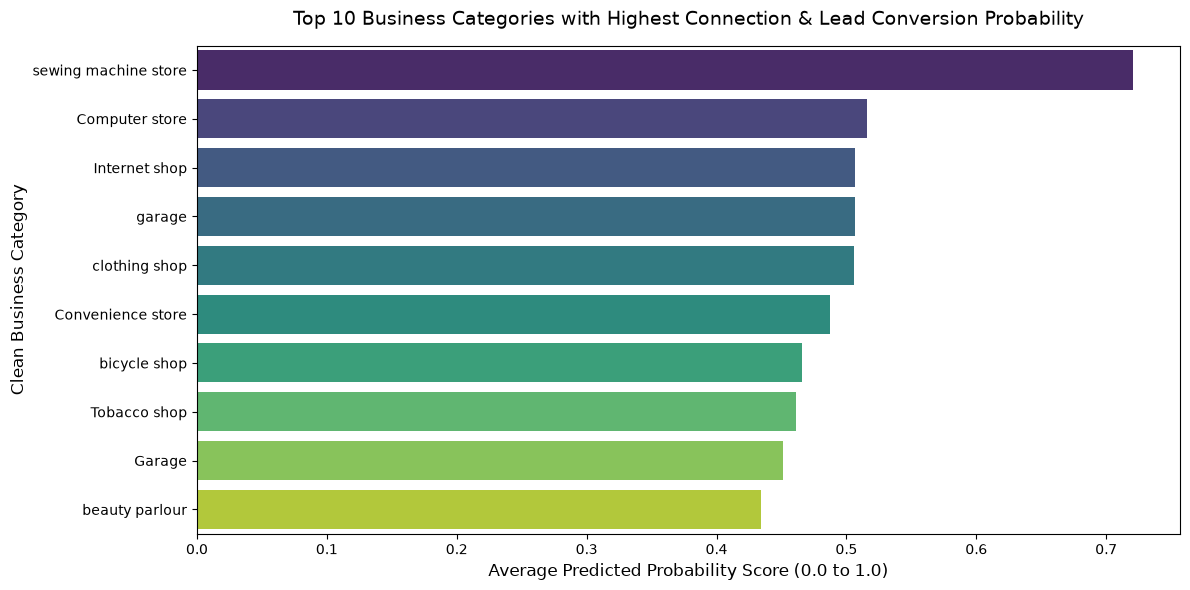

Visualization generated and saved successfully as 'top_converting_categories_updated.png'.


In [24]:
# Recombine high and medium priority data streams for category analysis
visualization_df = pd.concat([high_priority_final, medium_priority_final])

# Aggregate the mean predicted probability per business category using only the specified columns
category_performance = visualization_df.groupby('Category')['Predicted_Probability'].mean().reset_index()
category_performance_sorted = category_performance.sort_values(by='Predicted_Probability', ascending=False).head(10)

# Generate chart visualization
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(
    data=category_performance_sorted, 
    x='Predicted_Probability', 
    y='Category', 
    ax=ax, 
    palette='viridis',
    hue='Category'
)

ax.set_title('Top 10 Business Categories with Highest Connection & Lead Conversion Probability', fontsize=14, pad=15)
ax.set_xlabel('Average Predicted Probability Score (0.0 to 1.0)', fontsize=12)
ax.set_ylabel('Clean Business Category', fontsize=12)

plt.tight_layout()
plt.savefig('top_converting_categories_updated.png', dpi=300)
plt.show()
print("Visualization generated and saved successfully as 'top_converting_categories_updated.png'.")

In [25]:
import pandas as pd

check_file = pd.ExcelFile('Reviews_and_Comments_based_leads.xlsx')

print(check_file.sheet_names)

['High Priority (83)', 'Medium Priority (110)', 'Low Priority (108)']


In [26]:
print("Columns in final data:")
print(all_businesses.columns.tolist())

print("\nNumber of rows:", len(all_businesses))

Columns in final data:
['S.No', 'Country', 'City', 'Company', 'CONTACT', 'Google Map', 'Category', 'Standard_Category', 'Rank', 'Predicted_Probability']

Number of rows: 301


In [28]:
import os

# Required columns
required_columns = [
    'S.No',
    'Country',
    'City',
    'Company',
    'CONTACT',
    'Google Map',
    'Category',
    'Standard_Category',
    'Rank',
    'Predicted_Probability'
]

# Create priority datasets from all_businesses
high_excel = all_businesses.iloc[0:83][required_columns].copy()
medium_excel = all_businesses.iloc[83:193][required_columns].copy()
low_excel = all_businesses.iloc[193:301][required_columns].copy()

# Indian and Foreign datasets
indian_excel = all_businesses[
    all_businesses['Country'].astype(str).str.strip().str.lower() == 'india'
][required_columns].copy()

foreign_excel = all_businesses[
    all_businesses['Country'].astype(str).str.strip().str.lower() != 'india'
][required_columns].copy()

# Rename columns
def format_columns(data):
    return data.rename(columns={
        'S.No': 'S.No.',
        'CONTACT': 'Contact',
        'Google Map': 'Google Maps'
    })

high_excel = format_columns(high_excel)
medium_excel = format_columns(medium_excel)
low_excel = format_columns(low_excel)
indian_excel = format_columns(indian_excel)
foreign_excel = format_columns(foreign_excel)

# Output path
output_filename = os.path.join(
    os.getcwd(),
    'Reviews_and_Comments_based_leads.xlsx'
)

# Generate Excel
with pd.ExcelWriter(output_filename, engine='openpyxl') as writer:

    high_excel.to_excel(
        writer,
        sheet_name=f'High Priority ({len(high_excel)})',
        index=False
    )

    medium_excel.to_excel(
        writer,
        sheet_name=f'Medium Priority ({len(medium_excel)})',
        index=False
    )

    low_excel.to_excel(
        writer,
        sheet_name=f'Low Priority ({len(low_excel)})',
        index=False
    )

    indian_excel.to_excel(
        writer,
        sheet_name=f'Indian Businesses ({len(indian_excel)})',
        index=False
    )

    foreign_excel.to_excel(
        writer,
        sheet_name=f'Foreign Businesses ({len(foreign_excel)})',
        index=False
    )

print("======================================")
print("EXCEL GENERATED SUCCESSFULLY")
print("======================================")
print("File:", output_filename)
print()
print("High Priority:", len(high_excel))
print("Medium Priority:", len(medium_excel))
print("Low Priority:", len(low_excel))
print("Indian Businesses:", len(indian_excel))
print("Foreign Businesses:", len(foreign_excel))
print("Total:", len(all_businesses))
print()
print("Columns:")
print(high_excel.columns.tolist())

EXCEL GENERATED SUCCESSFULLY
File: C:\Users\pappu\OneDrive\Desktop\demo\BLC-10-main\Reviews_and_Comments_based_leads.xlsx

High Priority: 83
Medium Priority: 110
Low Priority: 108
Indian Businesses: 259
Foreign Businesses: 42
Total: 301

Columns:
['S.No.', 'Country', 'City', 'Company', 'Contact', 'Google Maps', 'Category', 'Standard_Category', 'Rank', 'Predicted_Probability']


In [29]:
import os

print("Notebook working folder:")
print(os.getcwd())

print("\nExcel file path:")
print(os.path.abspath("Reviews_and_Comments_based_leads.xlsx"))

print("\nDoes the file exist?")
print(os.path.exists("Reviews_and_Comments_based_leads.xlsx"))

Notebook working folder:
C:\Users\pappu\OneDrive\Desktop\demo\BLC-10-main

Excel file path:
C:\Users\pappu\OneDrive\Desktop\demo\BLC-10-main\Reviews_and_Comments_based_leads.xlsx

Does the file exist?
True


In [30]:
import pandas as pd

file_path = r"C:\Users\pappu\OneDrive\Desktop\demo\BLC-10-main\Reviews_and_Comments_based_leads.xlsx"

excel_file = pd.ExcelFile(file_path)

print("Sheets inside the Excel file:")
print(excel_file.sheet_names)

print("\nFirst sheet columns:")
first_sheet = pd.read_excel(file_path, sheet_name=excel_file.sheet_names[0])
print(first_sheet.columns.tolist())

print("\nFirst 3 rows:")
display(first_sheet.head(3))

Sheets inside the Excel file:
['High Priority (83)', 'Medium Priority (110)', 'Low Priority (108)', 'Indian Businesses (259)', 'Foreign Businesses (42)']

First sheet columns:
['S.No.', 'Country', 'City', 'Company', 'Contact', 'Google Maps', 'Category', 'Standard_Category', 'Rank', 'Predicted_Probability']

First 3 rows:


,S.No.,Country,City,Company,Contact,Google Maps,Category,Standard_Category,Rank,Predicted_Probability
0,1297,India,Jaipur,Tapri Central,9950966667,https://maps.app.goo.gl/TM4WCeHeTzPUAHvQ8,Cafe,Food & Hospitality,1,0.927540
1,1371,India,Jaipur,USHA Company Store,1412379210,https://maps.app.goo.gl/Di1oYeyTN2nNq23p9,sewing machine store,Other,2,0.720776
2,1272,India,Jaipur,Dr. H L Saini Associate Professor SMS medical ...,8619630817,https://maps.app.goo.gl/TtiK3KxNXAs92Nr76,Pharmacy,Other,3,0.535799


In [31]:
import os
import pandas as pd

file_path = r"C:\Users\pappu\OneDrive\Desktop\demo\BLC-10-main\Reviews_and_Comments_based_leads.xlsx"

print("File exists:", os.path.exists(file_path))
print("File location:", file_path)

excel = pd.ExcelFile(file_path)

print("\nACTUAL SHEETS IN FILE:")
for i, sheet in enumerate(excel.sheet_names, 1):
    print(i, "->", sheet)

File exists: True
File location: C:\Users\pappu\OneDrive\Desktop\demo\BLC-10-main\Reviews_and_Comments_based_leads.xlsx

ACTUAL SHEETS IN FILE:
1 -> High Priority (83)
2 -> Medium Priority (110)
3 -> Low Priority (108)
4 -> Indian Businesses (259)
5 -> Foreign Businesses (42)


In [32]:
import pandas as pd
import os

# ============================================================
# 1. CONTACT AVAILABILITY
# ============================================================

contact_data = df.copy()

contact_data['Contact_Status'] = contact_data['CONTACT'].apply(
    lambda x: 'Available'
    if pd.notna(x) and str(x).strip() not in ['', 'nan', 'None']
    else 'Not Available'
)

contact_availability = (
    contact_data['Contact_Status']
    .value_counts()
    .reset_index()
)

contact_availability.columns = ['Contact Status', 'Number of Businesses']


# ============================================================
# 2. COUNT OF COMPANY BY CATEGORY
# ============================================================

company_by_category = (
    df.groupby('Category')['Company']
    .count()
    .reset_index()
)

company_by_category.columns = ['Category', 'Number of Companies']

company_by_category = company_by_category.sort_values(
    'Number of Companies',
    ascending=False
)


# ============================================================
# 3. AVERAGE REVIEWS BY CATEGORY
# ============================================================

df['Reviews_Numeric'] = pd.to_numeric(
    df['Reviews'],
    errors='coerce'
)

avg_reviews_by_category = (
    df.groupby('Category')['Reviews_Numeric']
    .mean()
    .reset_index()
)

avg_reviews_by_category.columns = ['Category', 'Average Reviews']

avg_reviews_by_category['Average Reviews'] = (
    avg_reviews_by_category['Average Reviews']
    .round(2)
)

avg_reviews_by_category = avg_reviews_by_category.sort_values(
    'Average Reviews',
    ascending=False
)


# ============================================================
# 4. CATEGORY OF COMMENTS
# ============================================================
# For now, this gives comment-count groups.
# We will modify this later if your project specifies
# Positive / Neutral / Negative or another classification.

comment_category = df.copy()

comment_category['Comments_Numeric'] = pd.to_numeric(
    comment_category['Comment'],
    errors='coerce'
).fillna(0)

comment_category['Comment Category'] = pd.cut(
    comment_category['Comments_Numeric'],
    bins=[-1, 50, 200, float('inf')],
    labels=['Low Comments', 'Medium Comments', 'High Comments']
)

category_of_comments = (
    comment_category.groupby(
        ['Category', 'Comment Category'],
        observed=False
    )
    .size()
    .reset_index(name='Number of Businesses')
)


# ============================================================
# 5. CATEGORY DISTRIBUTION BY COUNTRY
# ============================================================

category_distribution_country = pd.crosstab(
    df['Country'],
    df['Category']
).reset_index()


# ============================================================
# 6. BUSINESSES BY CITY
# ============================================================

businesses_by_city = (
    df.groupby('City')['Company']
    .count()
    .reset_index()
)

businesses_by_city.columns = ['City', 'Number of Businesses']

businesses_by_city = businesses_by_city.sort_values(
    'Number of Businesses',
    ascending=False
)


# ============================================================
# ADD ALL 6 SHEETS TO EXISTING EXCEL FILE
# ============================================================

output_filename = os.path.join(
    os.getcwd(),
    'Reviews_and_Comments_based_leads.xlsx'
)

# IMPORTANT:
# mode='a' means ADD sheets to the existing workbook.
# It will NOT delete your existing 5 sheets.

with pd.ExcelWriter(
    output_filename,
    engine='openpyxl',
    mode='a',
    if_sheet_exists='replace'
) as writer:

    contact_availability.to_excel(
        writer,
        sheet_name='Contact Availability',
        index=False
    )

    company_by_category.to_excel(
        writer,
        sheet_name='Company by Category',
        index=False
    )

    avg_reviews_by_category.to_excel(
        writer,
        sheet_name='Avg Reviews by Category',
        index=False
    )

    category_of_comments.to_excel(
        writer,
        sheet_name='Category of Comments',
        index=False
    )

    category_distribution_country.to_excel(
        writer,
        sheet_name='Category by Country',
        index=False
    )

    businesses_by_city.to_excel(
        writer,
        sheet_name='Businesses by City',
        index=False
    )


# ============================================================
# FINAL CHECK
# ============================================================

print("==============================================")
print("6 ANALYTICS SHEETS CREATED SUCCESSFULLY")
print("==============================================")

print("Contact Availability:", len(contact_availability))
print("Company by Category:", len(company_by_category))
print("Avg Reviews by Category:", len(avg_reviews_by_category))
print("Category of Comments:", len(category_of_comments))
print("Category by Country:", len(category_distribution_country))
print("Businesses by City:", len(businesses_by_city))

print()
print("Excel file:")
print(output_filename)

6 ANALYTICS SHEETS CREATED SUCCESSFULLY
Contact Availability: 1
Company by Category: 39
Avg Reviews by Category: 39
Category of Comments: 117
Category by Country: 2
Businesses by City: 3

Excel file:
C:\Users\pappu\OneDrive\Desktop\demo\BLC-10-main\Reviews_and_Comments_based_leads.xlsx


In [33]:
print("Unique Cities:")
print(df['City'].value_counts())

print("\nUnique Countries:")
print(df['Country'].value_counts())

print("\nUnique Categories:")
print(df['Category'].nunique())
print(df['Category'].unique())

Unique Cities:
City
Jaipur            236
South Carolina     42
Patna              23
Name: count, dtype: int64

Unique Countries:
Country
India    259
USA       42
Name: count, dtype: int64

Unique Categories:
39
['cake shop and bakery' 'Convenience store' 'Petrol pump'
 "Men's clothing store" 'Tabacco shop' 'Pharmacy' 'mobile shop'
 'Tobacco shop' 'salvage shop' 'Tire shop' 'Vaporizer store'
 'Auto repair shop' 'Boat repair shop' 'Auto Service' 'Transmission shop'
 'Cafe' 'Towing services' 'Muffler shop' 'Electrician' 'Garage'
 'shopping shop' 'Internet shop' 'Gift shop' 'party store' 'garage'
 'Computer store' 'Pet store' 'sewing machine store' 'Department store'
 'Electronics store' 'General store' 'bicycle shop' 'beauty store'
 'electronics store' 'coffee shop' 'clothing shop' 'beauty parlour'
 'supermarket' 'General Store']


In [34]:
print(df[['Tech Need / Problem', 'Category']].head(20).to_string(index=False))

 Tech Need / Problem             Category
                 NaN cake shop and bakery
                 NaN cake shop and bakery
                 NaN cake shop and bakery
                 NaN cake shop and bakery
                 NaN cake shop and bakery
                 NaN cake shop and bakery
                 NaN cake shop and bakery
                 NaN cake shop and bakery
                 NaN cake shop and bakery
                 NaN cake shop and bakery
                 NaN    Convenience store
                 NaN    Convenience store
                 NaN    Convenience store
                 NaN    Convenience store
                 NaN    Convenience store
                 NaN cake shop and bakery
                 NaN cake shop and bakery
                 NaN cake shop and bakery
                 NaN cake shop and bakery
                 NaN cake shop and bakery


In [35]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nSample business information:")
print(
    df[['Company', 'Category', 'Reviews', 'Comment']]
    .head(20)
    .to_string(index=False)
)

Missing values in each column:
S.No                       0
Country                    0
City                       0
Company                    0
LINKEDIN LINK            301
Website                  301
Tech Need / Problem      301
EMAIL                    301
CONTACT                    0
Google Map                 0
Category                   0
Reviews                    0
Comment                    0
Reviews_Cleaned            0
Comments_Cleaned           0
Target_Label               0
Predicted_Probability      0
Priority                   0
Standard_Category          0
Reviews_Numeric            0
dtype: int64

Sample business information:
                                   Company             Category  Reviews  Comment
                            The cake corne cake shop and bakery      4.9      155
FNP CAKES N MORE by Ferns N Petals (Patna) cake shop and bakery      4.8      147
                                 Mr.bakers cake shop and bakery      4.3      172
                  

In [37]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

# ==========================================
# AI CATEGORY CLASSIFICATION
# ==========================================

category_df = df[['Company', 'Category']].copy()

# Clean company names
category_df['Company'] = (
    category_df['Company']
    .astype(str)
    .str.strip()
)

# Remove invalid company names
category_df = category_df[
    (category_df['Company'] != '') &
    (category_df['Company'] != 'nan')
].copy()

# Check category frequencies
category_counts = category_df['Category'].value_counts()

print("Category counts:")
print(category_counts)

# Keep categories having at least 2 records
valid_categories = category_counts[
    category_counts >= 2
].index

category_df = category_df[
    category_df['Category'].isin(valid_categories)
].copy()

print("\nRecords after removing one-record categories:", len(category_df))
print("Categories used:", category_df['Category'].nunique())

# ==========================================
# INPUT & TARGET
# ==========================================

X = category_df['Company']
y = category_df['Category']

# ==========================================
# TRAIN / TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ==========================================
# AI MODEL
# ==========================================

category_model = Pipeline([
    (
        'tfidf',
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2)
        )
    ),
    (
        'classifier',
        LogisticRegression(
            max_iter=2000
        )
    )
])

# Train
category_model.fit(X_train, y_train)

# Predict
y_pred = category_model.predict(X_test)

# ==========================================
# EVALUATION
# ==========================================

accuracy = accuracy_score(y_test, y_pred)

print("\n======================================")
print("AI CATEGORY CLASSIFICATION MODEL")
print("======================================")
print(f"Accuracy: {accuracy:.2%}")
print(f"Training Records: {len(X_train)}")
print(f"Testing Records: {len(X_test)}")
print(f"Categories Used: {y.nunique()}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Category counts:
Category
General Store           106
Pharmacy                 50
Garage                   30
cake shop and bakery     23
Cafe                     20
beauty parlour           12
Auto repair shop         11
Convenience store         9
garage                    7
Tabacco shop              3
Electronics store         2
mobile shop               1
Men's clothing store      1
Petrol pump               1
Tobacco shop              1
Transmission shop         1
Auto Service              1
Muffler shop              1
Towing services           1
Vaporizer store           1
Boat repair shop          1
Tire shop                 1
salvage shop              1
Gift shop                 1
Internet shop             1
shopping shop             1
Electrician               1
Pet store                 1
sewing machine store      1
Computer store            1
party store               1
General store             1
Department store          1
bicycle shop              1
beauty store          

In [38]:
# ==========================================
# PREDICT CATEGORY FOR ALL BUSINESSES
# ==========================================

df['Predicted_Category'] = category_model.predict(
    df['Company'].astype(str)
)

# Add prediction confidence
prediction_probabilities = category_model.predict_proba(
    df['Company'].astype(str)
)

df['Category_Predicted_Probability'] = (
    prediction_probabilities.max(axis=1)
)

# Round probability
df['Category_Predicted_Probability'] = (
    df['Category_Predicted_Probability'].round(4)
)

# Create AI classification output
ai_category_classification = df[
    [
        'S.No',
        'Country',
        'City',
        'Company',
        'Category',
        'Predicted_Category',
        'Category_Predicted_Probability'
    ]
].copy()

# Rename columns
ai_category_classification = ai_category_classification.rename(
    columns={
        'S.No': 'S.No.',
        'Category': 'Original Category',
        'Predicted_Category': 'AI Predicted Category',
        'Category_Predicted_Probability': 'Prediction Probability'
    }
)

print("======================================")
print("AI CATEGORY PREDICTIONS CREATED")
print("======================================")

print("Total Businesses:", len(ai_category_classification))

print("\nSample predictions:")
print(
    ai_category_classification.head(15).to_string(index=False)
)

AI CATEGORY PREDICTIONS CREATED
Total Businesses: 301

Sample predictions:
 S.No. Country           City                                    Company    Original Category AI Predicted Category  Prediction Probability
  1199   India          Patna                             The cake corne cake shop and bakery  cake shop and bakery                  0.3275
  1200   India          Patna FNP CAKES N MORE by Ferns N Petals (Patna) cake shop and bakery  cake shop and bakery                  0.2747
  1201   India          Patna                                  Mr.bakers cake shop and bakery         General Store                  0.2440
  1202   India          Patna                         Monginis Cake Shop cake shop and bakery  cake shop and bakery                  0.3302
  1203   India          Patna                     Downtown La Pasteleria cake shop and bakery         General Store                  0.2440
  1204   India          Patna                              Cakes & Bakes cake shop an

In [39]:
print(
    ai_category_classification[
        [
            'Company',
            'Original Category',
            'AI Predicted Category',
            'Prediction Probability'
        ]
    ].head(20).to_string(index=False)
)

                                   Company    Original Category AI Predicted Category  Prediction Probability
                            The cake corne cake shop and bakery  cake shop and bakery                  0.3275
FNP CAKES N MORE by Ferns N Petals (Patna) cake shop and bakery  cake shop and bakery                  0.2747
                                 Mr.bakers cake shop and bakery         General Store                  0.2440
                        Monginis Cake Shop cake shop and bakery  cake shop and bakery                  0.3302
                    Downtown La Pasteleria cake shop and bakery         General Store                  0.2440
                             Cakes & Bakes cake shop and bakery  cake shop and bakery                  0.2435
               Ganga Bakery & Cake Factory cake shop and bakery  cake shop and bakery                  0.4130
                           Cake Cafe Tales cake shop and bakery  cake shop and bakery                  0.3223
          

In [40]:
import os
import pandas as pd

output_filename = os.path.join(
    os.getcwd(),
    'Reviews_and_Comments_based_leads.xlsx'
)

with pd.ExcelWriter(
    output_filename,
    engine='openpyxl',
    mode='a',
    if_sheet_exists='replace'
) as writer:

    ai_category_classification.to_excel(
        writer,
        sheet_name='AI Category Classification',
        index=False
    )

print("======================================")
print("AI CATEGORY SHEET ADDED SUCCESSFULLY")
print("======================================")
print("Sheet: AI Category Classification")
print("Records:", len(ai_category_classification))
print("Excel:", output_filename)

AI CATEGORY SHEET ADDED SUCCESSFULLY
Sheet: AI Category Classification
Records: 301
Excel: C:\Users\pappu\OneDrive\Desktop\demo\BLC-10-main\Reviews_and_Comments_based_leads.xlsx
